In [1]:
import os
import pandas as pd


def doc_csv(ten_tep):
    """Doc tep csv trong thu muc data/, neu khong co thi doc o thu muc hien tai."""
    duong_dan = os.path.join("data", ten_tep)
    if not os.path.exists(duong_dan):
        duong_dan = ten_tep
    return pd.read_csv(duong_dan)

## 2. Tự viết K-Means

In [2]:
# -*- coding: utf-8 -*-
"""Bước 1: tự viết K-Means bằng numpy, chạy trên bảy điểm của slide.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np
from sklearn.cluster import KMeans

P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
                [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]


def k_means(X, tam, so_vong_toi_da=10):
    """K-Means don gian: gan diem vao tam gan nhat roi doi tam."""
    for vong in range(1, so_vong_toi_da + 1):
        # Bước gán: khoảng cách từ mỗi điểm tới mỗi tâm
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f" cum {k + 1}: {', '.join(ds)}")
        # Bước dời tâm: trung bình các điểm trong mỗi cụm
        tam_moi = np.array([X[nhan == k].mean(axis=0)
                            for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print(" Tam khong doi nua, dung.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan


# Khởi tạo cố ý tệ: hai tâm là A và B, nằm sát nhau
tam, nhan = k_means(P, P[[0, 1]].copy())
print()

# Tính inertia: tổng bình phương khoảng cách tới tâm cụm của mình
inertia = ((P - tam[nhan]) ** 2).sum()
print(f"Inertia tu tinh: {inertia:.4f}")

# So với scikit-learn, cho cùng tâm ban đầu
km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())

Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
 cum 1: A
 cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
 cum 1: A, B
 cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
 cum 1: A, B
 cum 2: C, D, E, F, G
 Tam khong doi nua, dung.

Inertia tu tinh: 8.5250
Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


## 3. Phân khúc khách hàng

In [3]:
# -*- coding: utf-8 -*-
"""Bước 2: phân khúc khách hàng bằng K-Means."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = doc_csv("khach_hang.csv")
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())
print()

X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_

# Tâm cụm đang ở thang đã chuẩn hoá, đổi ngược về đơn vị gốc để đọc
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_),
                    columns=["thu_nhap", "diem_chi_tieu"])
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("Tam cum, don vi goc:")
print(tam.round(1).to_string())
print()
print(f"Inertia: {km.inertia_:.2f}")
print()

# Khách mới: chuẩn hoá bằng đúng bộ chuẩn hoá cũ rồi tìm tâm gần nhất
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0],
                    "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]},"
        f" chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.3       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.8           22.0
50%     39.0      17.4           49.0
75%     46.0      28.6           77.0
max     62.0      35.5           99.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.4
3       8.0           18.9        40     44.9
4      30.2           81.5        40     32.6

Inertia: 23.02

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 4
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 0


## 4. Chọn số cụm K

In [4]:
# -*- coding: utf-8 -*-
"""Bước 3: chọn số cụm K bằng khuỷu tay và chỉ số silhouette."""

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = doc_csv("khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

print(" K     inertia   giam so voi K-1   silhouette")
truoc = None
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    # Silhouette cần ít nhất hai cụm
    sil = "" if k == 1 else f"{silhouette_score(Xs, km.labels_):.3f}"
    print(f" {k:2d}    {km.inertia_:7.1f}   {giam:>15s}   {sil:>10s}")
    truoc = km.inertia_

 K     inertia   giam so voi K-1   silhouette
  1      420.0                               
  2      250.4             169.6        0.430
  3      152.5              97.9        0.522
  4       73.8              78.8        0.626
  5       23.0              50.7        0.723
  6       20.9               2.1        0.651
  7       19.0               1.9        0.541
  8       17.4               1.6        0.454
  9       15.9               1.5        0.471
 10       14.4               1.4        0.425


## 5. Ba cái bẫy của K-Means

In [5]:
# -*- coding: utf-8 -*-
"""Bước 4: ba cái bẫy của K-Means."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = doc_csv("khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Bẫy 1: thu nhập ghi bằng nghìn đồng, không chuẩn hoá
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000         # đổi lại triệu đồng để dễ đọc
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f" ({t[0]:5.1f}, {t[1]:5.1f})")
print()

# Bẫy 2: mỗi lần chỉ khởi tạo ngẫu nhiên một lần
ket = []
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1,
                random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
print("Bay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket = sorted(ket)
print(" ", ket[:10])
print(" ", ket[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f" Voi n_init=10: inertia {tot.inertia_:.1f}")
print()

# Bẫy 3: cụm không tròn, dữ liệu hai vầng trăng
tr = doc_csv("hai_vang_trang.csv")
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan == tr["nhan"]).mean()
# Số thứ tự cụm có thể ngược với nhãn thật, nên lấy cách khớp tốt hơn
print(f"Bay 3: hai vang trang, ty le khop nhan that "
        f"{max(khop, 1 - khop):.4f}")

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
 (  6.1,  52.5)
 (  9.6,  41.9)
 ( 17.4,  49.8)
 ( 27.8,  52.9)
 ( 31.9,  52.4)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
  [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
  [72.4, 73.6, 73.7, 73.7, 84.0, 84.2, 84.2, 116.6, 117.4, 118.2]
 Voi n_init=10: inertia 23.0

Bay 3: hai vang trang, ty le khop nhan that 0.7500


## 6. Nén màu ảnh

In [6]:
# -*- coding: utf-8 -*-
"""Bước 5: nén màu một bức ảnh bằng K-Means."""

import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

anh = load_sample_image("china.jpg")        # ảnh có sẵn trong scikit-learn
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0           # mỗi dòng là một điểm ảnh RGB
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau")
print()

# Học trên 5000 điểm ảnh rút ngẫu nhiên cho nhanh, rồi gán cho mọi điểm
rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

print(" K    so bit moi diem   nho hon   sai lech trung binh")
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f" {k:2d}         {bit}                  {24 / bit:4.1f} lan"
          f"      {sai:5.2f} muc sang")

Anh 427 x 640, co 273280 diem anh, 96615 mau

 K    so bit moi diem   nho hon   sai lech trung binh
  4         2                  12.0 lan      17.41 muc sang
 16         4                   6.0 lan       7.97 muc sang
 64         6                   4.0 lan       4.54 muc sang


# 7. Bài tập

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import load_digits, load_sample_image
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# Du lieu khach hang va mo hinh K = 5 cua muc 3 (hai cot, co chuan hoa)
khach = doc_csv("khach_hang.csv")
hai_cot = ["thu_nhap", "diem_chi_tieu"]
bo_chuan_hoa = StandardScaler().fit(khach[hai_cot])
X_chuan = bo_chuan_hoa.transform(khach[hai_cot])

kmeans_5 = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_chuan)
nhan_5 = kmeans_5.labels_
tam_5 = pd.DataFrame(bo_chuan_hoa.inverse_transform(kmeans_5.cluster_centers_),
                     columns=hai_cot)
print(f"{len(khach)} khach hang, inertia voi K = 5: {kmeans_5.inertia_:.2f}")
print(tam_5.round(1).to_string())

210 khach hang, inertia voi K = 5: 23.02
   thu_nhap  diem_chi_tieu
0       7.5           80.2
1      30.1           20.0
2      17.4           49.3
3       8.0           18.9
4      30.2           81.5


## Bài tập 1: Tự tính silhouette

Silhouette trung binh tu tinh : 0.722706
silhouette_score cua thu vien : 0.722706

Silhouette trung binh theo cum
     count   mean    min
cum                     
0       35  0.711  0.343
1       35  0.765  0.476
2       60  0.692  0.029
3       40  0.749  0.244
4       40  0.716  0.303

Nam khach co s nho nhat
     thu_nhap  diem_chi_tieu  cum      a      b      s
113      25.4             41    2  0.918  0.945  0.029
70       13.7             34    2  0.734  0.831  0.117
205      13.1             29    3  0.685  0.906  0.244
165      27.4             63    4  0.816  1.170  0.303
105      25.2             69    4  0.763  1.113  0.314

Khach 113: thu nhap 25.4, chi tieu 41, thuoc cum 2
 tam cum cua khach : thu nhap 17.4, chi tieu 49.3, cach 0.877
 tam gan thu hai   : cum 1, thu nhap 30.1, chi tieu 20.0, cach 0.923


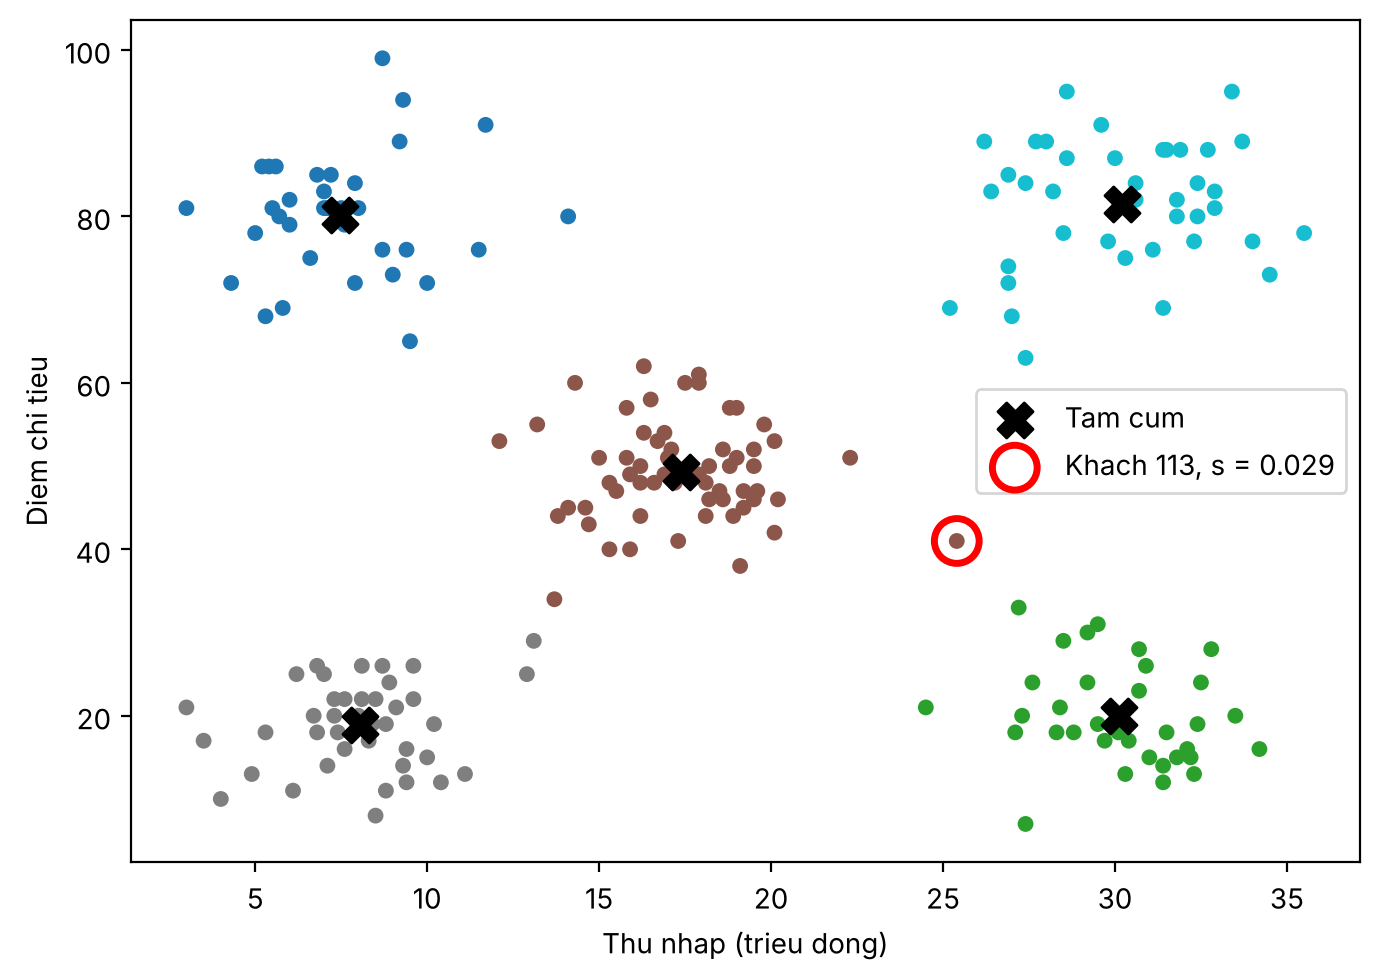

In [8]:
def silhouette_mot_diem(X, nhan, i):
    """Tra ve (a, b, s) cua diem thu i, chi dung numpy.

    a: khoang cach trung binh toi cac diem KHAC cung cum.
    b: khoang cach trung binh toi cac diem cua cum khac gan nhat.
    s = (b - a) / max(a, b).
    """
    khoang_cach = np.sqrt(((X - X[i]) ** 2).sum(axis=1))
    cung_cum = (nhan == nhan[i])
    so_ban_cung_cum = cung_cum.sum() - 1          # khong tinh chinh diem i
    if so_ban_cung_cum == 0:                      # cum chi co mot diem
        return 0.0, np.nan, 0.0
    a = khoang_cach[cung_cum].sum() / so_ban_cung_cum   # khoang cach toi chinh no bang 0
    b = min(khoang_cach[nhan == cum].mean()
            for cum in np.unique(nhan) if cum != nhan[i])
    return a, b, (b - a) / max(a, b)


ket_qua = np.array([silhouette_mot_diem(X_chuan, nhan_5, i)
                    for i in range(len(X_chuan))])
khach["a"], khach["b"], khach["s"] = ket_qua[:, 0], ket_qua[:, 1], ket_qua[:, 2]
khach["cum"] = nhan_5

print(f"Silhouette trung binh tu tinh : {khach['s'].mean():.6f}")
print(f"silhouette_score cua thu vien : {silhouette_score(X_chuan, nhan_5):.6f}")
print()

print("Silhouette trung binh theo cum")
print(khach.groupby("cum")["s"].agg(["count", "mean", "min"]).round(3).to_string())
print()

i_min = int(khach["s"].idxmin())
khach_min = khach.loc[i_min]
print("Nam khach co s nho nhat")
print(khach.nsmallest(5, "s")[["thu_nhap", "diem_chi_tieu", "cum", "a", "b", "s"]]
      .round(3).to_string())
print()

# Khach do gan tam nao nhat, tam nao nhi
kc_toi_tam = np.sqrt(((kmeans_5.cluster_centers_ - X_chuan[i_min]) ** 2).sum(axis=1))
thu_tu = np.argsort(kc_toi_tam)
print(f"Khach {i_min}: thu nhap {khach_min['thu_nhap']}, chi tieu {khach_min['diem_chi_tieu']:.0f}, "
      f"thuoc cum {int(khach_min['cum'])}")
print(f" tam cum cua khach : thu nhap {tam_5.loc[thu_tu[0], 'thu_nhap']:.1f}, "
      f"chi tieu {tam_5.loc[thu_tu[0], 'diem_chi_tieu']:.1f}, cach {kc_toi_tam[thu_tu[0]]:.3f}")
print(f" tam gan thu hai   : cum {thu_tu[1]}, thu nhap {tam_5.loc[thu_tu[1], 'thu_nhap']:.1f}, "
      f"chi tieu {tam_5.loc[thu_tu[1], 'diem_chi_tieu']:.1f}, cach {kc_toi_tam[thu_tu[1]]:.3f}")

# Ve lai hinh phan cum, danh dau khach co s nho nhat
plt.figure(figsize=(7, 5))
plt.scatter(khach["thu_nhap"], khach["diem_chi_tieu"], c=nhan_5, cmap="tab10", s=22)
plt.scatter(tam_5["thu_nhap"], tam_5["diem_chi_tieu"], marker="X", s=160,
            c="black", label="Tam cum")
plt.scatter(khach_min["thu_nhap"], khach_min["diem_chi_tieu"], s=260,
            facecolors="none", edgecolors="red", linewidths=2.5,
            label=f"Khach {i_min}, s = {khach_min['s']:.3f}")
plt.xlabel("Thu nhap (trieu dong)")
plt.ylabel("Diem chi tieu")
plt.legend()
plt.tight_layout()
plt.show()

**Nhận xét:** Trung bình silhouette tự tính trên 210 khách là 0.722706, trùng với `silhouette_score` của thư viện tới sáu chữ số thập phân
Khách có s nhỏ thứ hai (0.117, thu nhập 13.7, chi tiêu 34) cũng thuộc cụm giữa, nằm ở rìa dưới bên trái hướng về cụm thu nhập thấp, chi tiêu thấp. Vì vậy cụm giữa có silhouette trung bình thấp nhất (0.692): nó nằm giữa bốn cụm còn lại nên các điểm ở rìa đều gần một cụm khác. Không khách nào có s âm, tức không ai bị xếp sai cụm một cách rõ ràng.

## Bài tập 2: Thêm cột tuổi

In [9]:
ba_cot = ["tuoi", "thu_nhap", "diem_chi_tieu"]
bo_chuan_hoa_3 = StandardScaler().fit(khach[ba_cot])
X_chuan_3 = bo_chuan_hoa_3.transform(khach[ba_cot])

print(" K   silhouette (ba cot)   silhouette (hai cot)")
diem_ba_cot = {}
for k in range(2, 11):
    km_3 = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_chuan_3)
    km_2 = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_chuan)
    diem_ba_cot[k] = silhouette_score(X_chuan_3, km_3.labels_)
    print(f" {k:2d}        {diem_ba_cot[k]:.3f}                 "
          f"{silhouette_score(X_chuan, km_2.labels_):.3f}")
k_tot_3 = max(diem_ba_cot, key=diem_ba_cot.get)
print(f"K tot nhat voi ba cot: {k_tot_3}")
print()

kmeans_3_cot = KMeans(n_clusters=k_tot_3, n_init=10, random_state=0).fit(X_chuan_3)
tam_3_cot = pd.DataFrame(
    bo_chuan_hoa_3.inverse_transform(kmeans_3_cot.cluster_centers_), columns=ba_cot)
tam_3_cot["so_khach"] = np.bincount(kmeans_3_cot.labels_)
print(f"Tam cum voi ba cot, K = {k_tot_3}, don vi goc:")
print(tam_3_cot.sort_values("thu_nhap").round(1).to_string(index=False))
print()

tam_muc_3 = tam_5.copy()
tam_muc_3["so_khach"] = np.bincount(nhan_5)
tam_muc_3["tuoi_tb"] = khach.groupby(nhan_5)["tuoi"].mean()
print("Tam cum cua muc 3 (hai cot, K = 5):")
print(tam_muc_3.sort_values("thu_nhap").round(1).to_string(index=False))
print()
print("Bang cheo: hang la cum hai cot, cot la cum ba cot")
print(pd.crosstab(nhan_5, kmeans_3_cot.labels_).to_string())

 K   silhouette (ba cot)   silhouette (hai cot)
  2        0.373                 0.430
  3        0.422                 0.522


  4        0.456                 0.626


  5        0.481                 0.723
  6        0.476                 0.651
  7        0.463                 0.541
  8        0.460                 0.454
  9        0.462                 0.471
 10        0.457                 0.425
K tot nhat voi ba cot: 5

Tam cum voi ba cot, K = 5, don vi goc:
 tuoi  thu_nhap  diem_chi_tieu  so_khach
 44.9       8.0           18.9        40
 25.1       8.5           77.6        39
 41.6      17.6           49.2        57
 42.9      30.1           20.0        35
 32.1      30.3           82.0        39

Tam cum cua muc 3 (hai cot, K = 5):
 thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
      7.5           80.2        35     24.9
      8.0           18.9        40     44.9
     17.4           49.3        60     40.4
     30.1           20.0        35     42.9
     30.2           81.5        40     32.6

Bang cheo: hang la cum hai cot, cot la cum ba cot
col_0   0   1   2   3   4
row_0                    
0       0  35   0   0   0
1       0   0  35   0   0

**Nhận xét:** K tốt nhất **vẫn là 5**: với ba cột, silhouette cao nhất là 0.481 ở K = 5. Tuy nhiên đỉnh không còn rõ như trước: K = 6 đạt 0.476, gần bằng, và mọi giá trị silhouette đều thấp hơn hẳn trường hợp hai cột (0.481 so với 0.723 ở K = 5). Thêm cột tuổi làm các cụm kém tách bạch hơn, vì tuổi trải rộng trong từng nhóm và không chia khách thành những khối riêng như thu nhập và điểm chi tiêu.

## Bài tập 3: K-Means++ và khởi tạo ngẫu nhiên

In [10]:
INERTIA_TOT_NHAT = 23.0
ket_qua_khoi_tao = {}
for cach in ["random", "k-means++"]:
    cac_inertia = []
    for rs in range(50):
        km = KMeans(n_clusters=5, init=cach, n_init=1, random_state=rs).fit(X_chuan)
        cac_inertia.append(round(km.inertia_, 1))
    ket_qua_khoi_tao[cach] = np.array(cac_inertia)

print("Cach khoi tao   so lan dat 23.0   inertia trung binh   inertia xau nhat")
for cach, ds in ket_qua_khoi_tao.items():
    so_lan = int((ds == INERTIA_TOT_NHAT).sum())
    print(f" {cach:10s}        {so_lan:2d} / 50           {ds.mean():7.1f}            {ds.max():7.1f}")
print()
for cach, ds in ket_qua_khoi_tao.items():
    gia_tri, so_lan = np.unique(ds, return_counts=True)
    print(f"{cach}: cac muc inertia va so lan gap")
    print("  ", ", ".join(f"{g}: {s}" for g, s in zip(gia_tri, so_lan)))

Cach khoi tao   so lan dat 23.0   inertia trung binh   inertia xau nhat
 random            30 / 50              53.3              204.0
 k-means++         50 / 50              23.0               23.0

random: cac muc inertia va so lan gap
   23.0: 30, 72.4: 2, 73.3: 1, 73.6: 1, 73.7: 2, 84.0: 1, 84.1: 2, 84.2: 2, 84.9: 1, 116.6: 2, 117.4: 1, 118.2: 2, 119.3: 2, 204.0: 1
k-means++: cac muc inertia va so lan gap
   23.0: 50


**Nhận xét:** Trong 50 lần chạy với `n_init=1`, khởi tạo ngẫu nhiên (`init="random"`) chỉ đạt inertia 23.0 ở **30 lần**, còn K-Means++ đạt 23.0 ở **cả 50 lần**. Inertia trung bình của khởi tạo ngẫu nhiên là 53.3, lần xấu nhất lên tới 204.0, gấp gần 9 lần mức tốt nhất. K-Means++ đáng tin hơn hẳn.

## Bài tập 4: Lưu ảnh đã nén

Dang cua anh_moi: (427, 640, 3)


anh_goc.png    :   548.2 KB
anh_16_mau.png :   142.0 KB, con 16 mau, nho hon 3.86 lan

anh_cua_em.png: dang (427, 640, 4), kieu float32
Sau khi bo kenh trong suot va nen: dang (427, 640, 3)
anh_cua_em.png        :   427.6 KB
anh_cua_em_16_mau.png :    60.2 KB, nho hon 7.10 lan


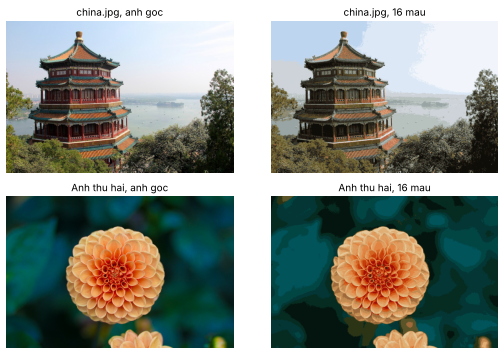

In [11]:
import os


def nen_mau(anh, so_mau=16, so_diem_hoc=5000, hat_giong=0):
    """Nen mau mot buc anh bang K-Means. Tra ve mang (cao, rong, 3) trong khoang 0..1."""
    anh = np.asarray(anh)
    if anh.ndim == 3 and anh.shape[2] == 4:
        anh = anh[:, :, :3]                 # bo kenh thu tu la do trong suot
    if anh.dtype == np.uint8:
        anh = anh / 255.0                   # dua ve khoang 0..1
    cao, rong, _ = anh.shape
    diem_anh = anh.reshape(-1, 3)
    rng = np.random.default_rng(hat_giong)
    mau_hoc = diem_anh[rng.choice(len(diem_anh), so_diem_hoc, replace=False)]
    km = KMeans(n_clusters=so_mau, n_init=4, random_state=0).fit(mau_hoc)
    anh_moi = km.cluster_centers_[km.predict(diem_anh)].reshape(cao, rong, 3)
    return np.clip(anh_moi, 0, 1)


def kich_thuoc_kb(ten_tep):
    return os.path.getsize(ten_tep) / 1024


# Phan 1: anh china.jpg co san trong scikit-learn
anh_goc = load_sample_image("china.jpg")
anh_moi = nen_mau(anh_goc, so_mau=16)
print("Dang cua anh_moi:", anh_moi.shape)
plt.imsave("anh_goc.png", anh_goc)
plt.imsave("anh_16_mau.png", anh_moi)

kb_goc, kb_nen = kich_thuoc_kb("anh_goc.png"), kich_thuoc_kb("anh_16_mau.png")
so_mau_con_lai = len(np.unique((anh_moi * 255).round().astype(int).reshape(-1, 3), axis=0))
print(f"anh_goc.png    : {kb_goc:7.1f} KB")
print(f"anh_16_mau.png : {kb_nen:7.1f} KB, con {so_mau_con_lai} mau, "
      f"nho hon {kb_goc / kb_nen:.2f} lan")
print()

# Phan 2: mot buc anh khac doc bang plt.imread.
# O day dung anh flower.jpg cua scikit-learn, luu thanh PNG co kenh trong suot
# de thu nhanh bo kenh thu tu. Thay TEN_ANH bang anh cua chinh minh de lam lai.
TEN_ANH = "anh_cua_em.png"
if not os.path.exists(TEN_ANH):
    hoa = load_sample_image("flower.jpg") / 255.0
    hoa_co_alpha = np.dstack([hoa, np.ones(hoa.shape[:2])])
    plt.imsave(TEN_ANH, hoa_co_alpha)

anh_rieng = plt.imread(TEN_ANH)
print(f"{TEN_ANH}: dang {anh_rieng.shape}, kieu {anh_rieng.dtype}")
anh_rieng_16 = nen_mau(anh_rieng, so_mau=16)
plt.imsave("anh_cua_em_16_mau.png", anh_rieng_16)
kb_rieng, kb_rieng_nen = kich_thuoc_kb(TEN_ANH), kich_thuoc_kb("anh_cua_em_16_mau.png")
print(f"Sau khi bo kenh trong suot va nen: dang {anh_rieng_16.shape}")
print(f"{TEN_ANH}        : {kb_rieng:7.1f} KB")
print(f"anh_cua_em_16_mau.png : {kb_rieng_nen:7.1f} KB, nho hon {kb_rieng / kb_rieng_nen:.2f} lan")

fig, truc = plt.subplots(2, 2, figsize=(9, 6), dpi=60)
for ax, hinh, ten in zip(truc.ravel(),
                         [anh_goc, anh_moi, anh_rieng[:, :, :3], anh_rieng_16],
                         ["china.jpg, anh goc", "china.jpg, 16 mau",
                          "Anh thu hai, anh goc", "Anh thu hai, 16 mau"]):
    ax.imshow(hinh)
    ax.set_title(ten)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:** Ảnh `china.jpg` sau khi nén còn đúng 16 màu, mảng `anh_moi` có dạng (427, 640, 3). Tệp `anh_goc.png` nặng 548.2 KB, tệp `anh_16_mau.png` nặng 142.0 KB, **nhỏ hơn 3.86 lần**.

Con số này thấp hơn mức 6 lần tính theo số bit ở mục 6 (24 bit xuống 4 bit mỗi điểm ảnh), vì hai lý do. Thứ nhất, `plt.imsave` vẫn lưu ảnh 16 màu dưới dạng đủ ba kênh màu cho mỗi điểm ảnh, không lưu bảng 16 màu kèm số thứ tự. Thứ hai, PNG tự nén không mất dữ liệu, nên ảnh gốc cũng đã được nén một phần. Ảnh 16 màu nhỏ hơn là vì có nhiều vùng cùng màu lặp lại, bộ nén PNG làm việc hiệu quả hơn. Muốn đạt đúng mức 6 lần thì phải lưu ảnh ở dạng có bảng màu.

**Bức ảnh thứ hai:** ô code đọc ảnh bằng `plt.imread`, được mảng (427, 640, 4) kiểu `float32`, tức có kênh thứ tư là độ trong suốt. Hàm `nen_mau` bỏ kênh đó bằng `anh[:, :, :3]` trước khi phân cụm, kết quả có dạng (427, 640, 3). Tệp giảm từ 427.6 KB xuống 60.2 KB, nhỏ hơn 7.10 lần, một phần vì tệp gốc còn phải lưu thêm kênh trong suốt. Tỷ lệ nén khác nhau giữa hai ảnh vì nó phụ thuộc vào nội dung: ảnh có nhiều mảng màu đồng đều thì nén được nhiều hơn.

**Cần thay ảnh:** bức ảnh thứ hai trong notebook này là `flower.jpg` có sẵn của scikit-learn, được lưu lại thành PNG có kênh trong suốt để thử đúng trường hợp đề nêu. Đề yêu cầu ảnh của chính em, nên em cần đặt ảnh của mình cạnh notebook, sửa biến `TEN_ANH` rồi chạy lại ô này và cập nhật các con số ở đoạn trên.

## Bài tập 5: DBSCAN trên hai vầng trăng

K-Means, K = 2: ty le khop 0.7500, ARI 0.2475

 eps   so cum   diem nhieu   co cac cum      ty le khop    ARI
 0.2       1        40       [260]           0.4367     -0.0014
 0.3       1        10       [290]           0.4933     0.0012
 0.4       1         3       [297]           0.4967     -0.0001

Thu them eps nho hon
 eps    so cum   diem nhieu   cum lon nhat   ty le khop    ARI
 0.10      6       257          12         0.1233     0.0039
 0.15     16        99          46         0.5800     0.0542
 0.18      5        50         167         0.5767     0.0603


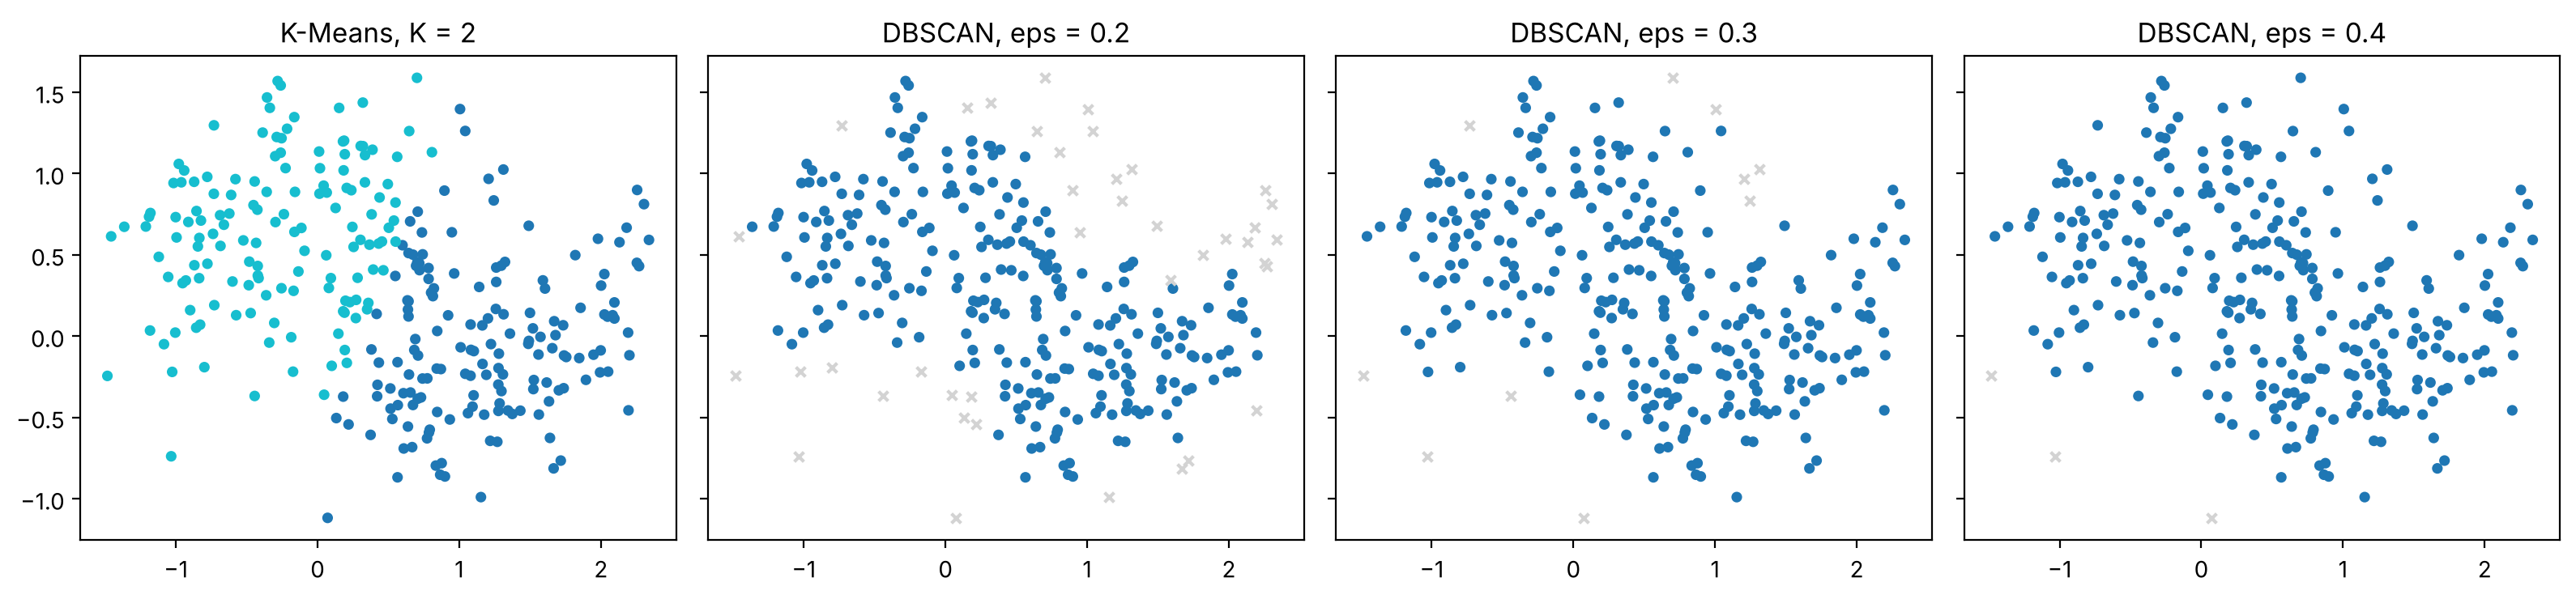

In [12]:
trang = doc_csv("hai_vang_trang.csv")
X_trang = trang[["x1", "x2"]].to_numpy()
nhan_that = trang["nhan"].to_numpy()


def ty_le_khop(nhan_cum):
    """Gan moi cum cho lop chiem da so trong cum do, diem nhieu tinh la sai."""
    dung = 0
    for cum in np.unique(nhan_cum):
        if cum == -1:
            continue
        dung += np.bincount(nhan_that[nhan_cum == cum]).max()
    return dung / len(nhan_that)


nhan_kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_trang)
print(f"K-Means, K = 2: ty le khop {ty_le_khop(nhan_kmeans):.4f}, "
      f"ARI {adjusted_rand_score(nhan_that, nhan_kmeans):.4f}")
print()

print(" eps   so cum   diem nhieu   co cac cum      ty le khop    ARI")
nhan_dbscan = {}
for eps in [0.2, 0.3, 0.4]:
    nhan_dbscan[eps] = DBSCAN(eps=eps, min_samples=5).fit_predict(X_trang)
    nhan = nhan_dbscan[eps]
    so_cum = len(set(nhan)) - (1 if -1 in nhan else 0)
    co_cum = sorted((int(v) for v in np.bincount(nhan[nhan >= 0])), reverse=True)
    print(f" {eps:.1f}    {so_cum:4d}      {int((nhan == -1).sum()):4d}       "
          f"{str(co_cum):14s}  {ty_le_khop(nhan):.4f}     "
          f"{adjusted_rand_score(nhan_that, nhan):.4f}")
print()

# Thu them vai gia tri nho hon de thay ro vai tro cua eps
print("Thu them eps nho hon")
print(" eps    so cum   diem nhieu   cum lon nhat   ty le khop    ARI")
for eps in [0.10, 0.15, 0.18]:
    nhan = DBSCAN(eps=eps, min_samples=5).fit_predict(X_trang)
    so_cum = len(set(nhan)) - (1 if -1 in nhan else 0)
    print(f" {eps:.2f}   {so_cum:4d}      {int((nhan == -1).sum()):4d}        "
          f"{int(np.bincount(nhan[nhan >= 0]).max()):4d}         {ty_le_khop(nhan):.4f}     "
          f"{adjusted_rand_score(nhan_that, nhan):.4f}")

fig, truc = plt.subplots(1, 4, figsize=(16, 3.8), sharex=True, sharey=True)
for ax, (ten, nhan) in zip(truc, [("K-Means, K = 2", nhan_kmeans)]
                           + [(f"DBSCAN, eps = {e}", nhan_dbscan[e]) for e in [0.2, 0.3, 0.4]]):
    nhieu = nhan == -1
    ax.scatter(X_trang[~nhieu, 0], X_trang[~nhieu, 1], c=nhan[~nhieu], cmap="tab10", s=14)
    ax.scatter(X_trang[nhieu, 0], X_trang[nhieu, 1], c="lightgray", marker="x", s=18)
    ax.set_title(ten)
plt.tight_layout()
plt.show()

**Nhận xét:** Với cả ba giá trị đề yêu cầu, DBSCAN chỉ tìm được **một cụm**:

| eps | Số cụm | Điểm nhiễu |
|---|---|---|
| 0.2 | 1 | 40 |
| 0.3 | 1 | 10 |
| 0.4 | 1 | 3 |

**Không có giá trị nào tách được hai vầng trăng tốt hơn K-Means.** K-Means với K = 2 khớp nhãn thật 0.7500 (ARI 0.2475). DBSCAN gom gần hết 300 điểm vào một cụm nên tỷ lệ khớp chỉ khoảng 0.44 đến 0.50 và ARI xấp xỉ 0, tức không tốt hơn đoán bừa. Lý do nằm ở dữ liệu: hai vầng trăng trong tệp này có nhiễu lớn nên dính vào nhau ở phần giữa, không có khoảng trống mật độ thấp nào ngăn cách chúng. DBSCAN nối các điểm gần nhau thành chuỗi, nên chỉ cần một dải điểm nối hai vầng là cả hai bị gộp làm một.

**Vai trò của eps:** eps là bán kính để coi hai điểm là hàng xóm. Một điểm có ít nhất `min_samples` hàng xóm trong bán kính đó thì thành điểm lõi, các điểm lõi gần nhau nối thành cụm, điểm không thuộc cụm nào bị gán nhãn −1. Khi eps tăng từ 0.2 lên 0.4, số điểm nhiễu giảm từ 40 xuống 3 vì bán kính lớn hơn bắt được cả những điểm ở rìa. Bảng thử thêm cho thấy chiều ngược lại: eps = 0.18 cho 5 cụm và 50 điểm nhiễu, eps = 0.15 cho 16 cụm vụn và 99 điểm nhiễu, eps = 0.10 thì 257 trên 300 điểm bị coi là nhiễu. Như vậy eps quá lớn thì mọi thứ dính thành một cụm, eps quá nhỏ thì dữ liệu vỡ vụn, và trên bộ dữ liệu này không có khoảng giữa nào cho ra đúng hai cụm.

Bài học: DBSCAN có ưu điểm là không cần chọn K, tìm được cụm hình dạng bất kỳ và tự đánh dấu điểm nhiễu, nhưng nó chỉ tách được các cụm khi giữa chúng có vùng thưa điểm. Với hai vầng trăng sạch hơn (ít nhiễu) thì DBSCAN thường tách được, còn ở đây thì không. Kết luận này chỉ đúng cho `min_samples=5` và các giá trị eps đã thử.

## Bài tập 6: Phân cụm chữ số viết tay

cum            0    1    2   3    4    5    6    7    8    9
chu so that                                                 
0            176    0    0   0    0    0    2    0    0    0
1              0  100    0  54    1    2    0    1    0   24
2              1    8    3   2   13    0    0    0    2  148
3              0    7    7   0  154    0    0    2   13    0
4              0    2   11   3    0    0  165    0    0    0
5              0    0    0   0    2    1    2  136   41    0
6              1    3    0   0    0  177    0    0    0    0
7              0    2  174   2    0    0    0    1    0    0
8              0  100    5   6    2    2    0    4   52    3
9              0    1    8  20    6    0    0    6  139    0

Moi chu so: cum chua nhieu anh nhat va ty le anh nam trong cum do
 chu so 0: cum 0, 176 / 178 anh (99%)
 chu so 1: cum 1, 100 / 182 anh (55%)
 chu so 2: cum 9, 148 / 177 anh (84%)
 chu so 3: cum 4, 154 / 183 anh (84%)
 chu so 4: cum 6, 165 / 181 anh (91%)
 chu so 5: 

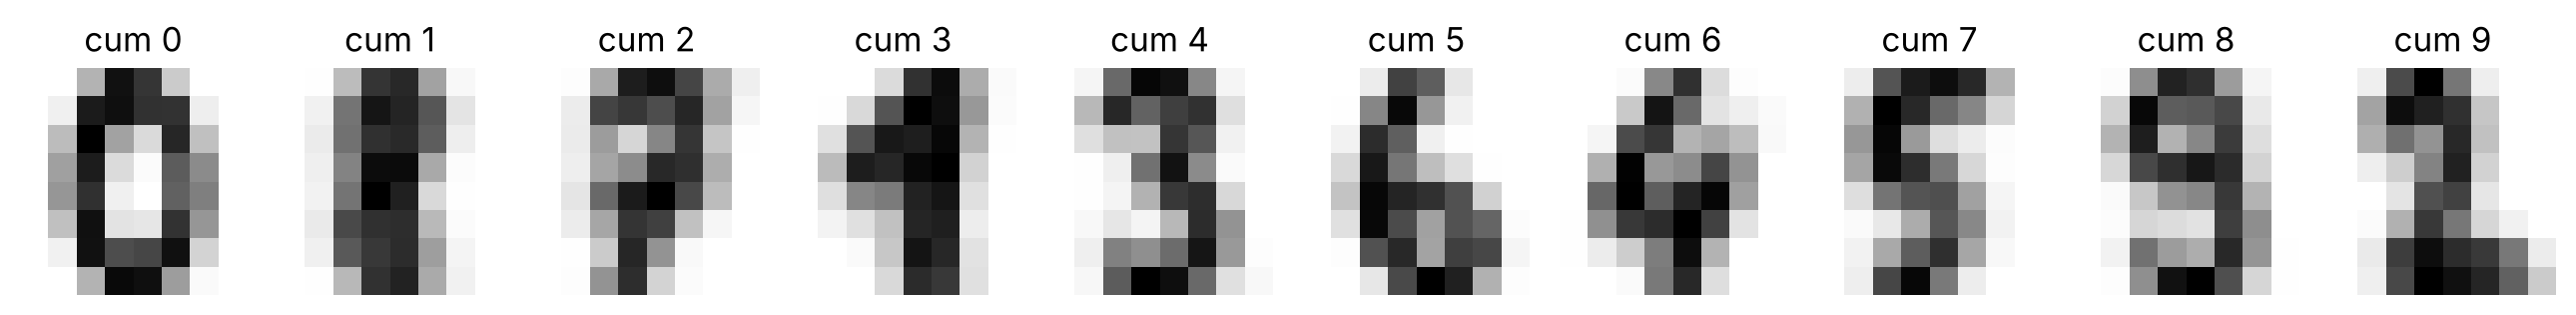

In [13]:
X_chu, nhan_that_chu = load_digits(return_X_y=True)

# Phan cum khong dung nhan
kmeans_chu = KMeans(n_clusters=10, n_init=10, random_state=0).fit(X_chu)
cum_chu = kmeans_chu.labels_

# Sau do moi dung nhan that de doc ket qua
bang_cheo = pd.crosstab(pd.Series(nhan_that_chu, name="chu so that"),
                        pd.Series(cum_chu, name="cum"))
print(bang_cheo.to_string())
print()

print("Moi chu so: cum chua nhieu anh nhat va ty le anh nam trong cum do")
for chu_so in range(10):
    hang = bang_cheo.loc[chu_so]
    print(f" chu so {chu_so}: cum {hang.idxmax()}, {hang.max():3d} / {hang.sum()} anh "
          f"({hang.max() / hang.sum():.0%})")
print()

print("Moi cum: cac chu so chiem tu 10% so anh cua cum tro len")
for cum in range(10):
    cot = bang_cheo[cum]
    chinh = [f"{so} ({cot[so]})" for so in cot.sort_values(ascending=False).index
             if cot[so] >= 0.10 * cot.sum()]
    print(f" cum {cum} ({cot.sum():3d} anh): " + ", ".join(chinh))
print()
print(f"Ty le khop neu gan moi cum cho chu so chiem da so: "
      f"{bang_cheo.max(axis=0).sum() / len(X_chu):.4f}")

# Ve 10 tam cum thanh anh 8 x 8
fig, truc = plt.subplots(1, 10, figsize=(13, 1.8))
for cum, ax in enumerate(truc):
    ax.imshow(kmeans_chu.cluster_centers_[cum].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"cum {cum}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:** K-Means không được xem nhãn, vậy mà nếu gán mỗi cụm cho chữ số chiếm đa số thì khớp với nhãn thật 0.7919.

**Chữ số được gom gọn vào một cụm:** số 0 (176 trên 178 ảnh nằm trong cụm 0, tức 99%), số 6 (177 trên 181, 98%), số 7 (174 trên 179, 97%) và số 4 (165 trên 181, 91%). Các cụm tương ứng cũng gần như chỉ chứa đúng chữ số đó, ví dụ cụm 0 có 176 trên 178 ảnh là số 0. Số 2 và số 3 ở mức khá (84%).

**Chữ số hay bị gom chung:**
- **Số 1 và số 8** cùng nằm trong cụm 1, mỗi số đúng 100 ảnh. Cụm này không tách được hai chữ số đó.
- **Số 9, số 8 và số 5** cùng nằm trong cụm 8 (139 ảnh số 9, 52 ảnh số 8, 41 ảnh số 5).
- **Số 1 bị chia ra ba cụm**: 100 ảnh ở cụm 1, 54 ảnh ở cụm 3 và 24 ảnh ở cụm 9 (chung với số 2). Số 8 cũng không có cụm riêng: 100 ảnh ở cụm 1 và 52 ảnh ở cụm 8.